# Random seed

In [1]:
import os
import random
import numpy as np

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Для будущей реализации FM на PyTorch
try:
    import torch

    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)

except ImportError:
    pass

# Датасет

Датасет **KuaiRec** — это открытый набор реальных данных, собранных из логов китайской платформы для обмена короткими видео Kuaishou. Он содержит информацию о взаимодействиях пользователей с видео, а также дополнительные характеристики пользователей и объектов.

Основу датасета составляют две таблицы взаимодействий — *small_matrix.csv* и *big_matrix.csv* - это матрицы с различной степенью заполненности.


*   **small_matrix** содержит 4 676 570 взаимодействий 1 411 пользователей с 3327 видео, заполненность *99,6%*

*   **big_matrix** содержит 12 530 806 взаимодействий 7 176 пользователей с 10 728 видео при заполненности около *16,3%*

Каждая запись описывает взаимодействие пользователя с определённым видео. Для каждой пары пользователя и видео доступны идентификаторы `user_id` и `video_id`, длительность просмотра `play_duration`, длительность видео `video_duration` и временная метка взаимодействия `timestamp`. На основе этих данных рассчитывается показатель **`watch_ratio`**, представляющий собой отношение времени просмотра к продолжительности видео. Он используется в качестве количественного сигнала предпочтения: более высокие значения могут свидетельствовать о большем интересе пользователя к контенту, хотя этот показатель не является прямой оценкой удовлетворенности.

Помимо пользовательских взаимодействий, в датасете представлены дополнительные признаки. Файл user_features.csv содержит характеристики пользователей, item_categories.csv — категории видео, а item_daily_features.csv — ежедневную статистику и характеристики объектов. Файл social_network.csv описывает связи между пользователями. Эти сведения позволяют использовать не только историю взаимодействий, но и метапризнаки пользователей и видео, что особенно важно для построения факторизационной машины (FM).

В данной работе KuaiRec используется для решения задачи персонализированного ранжирования видео. Для каждого пользователя необходимо сформировать top-10 видео, которые предположительно будут ему наиболее интересны. Качество рекомендаций оценивается на отложенных взаимодействиях, которые не использовались при обучении моделей. Поскольку датасет содержит временные метки, для разделения данных на обучающую, валидационную и тестовую выборки используется временной принцип. Для обеспечения воспроизводимости фиксируется random_seed.

**Источник данных:** [KuaiRec — официальный репозиторий GitHub](https://github.com/chongminggao/KuaiRec), [страница проекта](https://kuairec.com/).

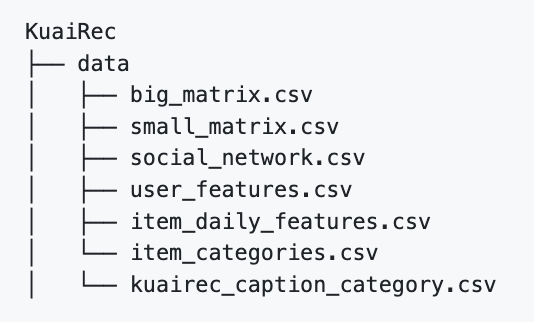

Авторы пишут:  

> *"We provide some basic statistics of the KuaiRec dataset. The description of this dataset can be referred to https://chongminggao.github.io/KuaiRec/"*

Поэтому возьмем часть реализованной ими аналитики

## EDA based on [Statistics of KuaiRec](https://kuairec.com/Statistics_KuaiRec.html)

### Load data

If you are using Google Colab, make sure you have added shortcut of this [shared link](https://drive.google.com/drive/folders/1bAm07YnKRKB6SVHB8Mqz6v6W8ppLaJwB) to your own Google Drive. Then, you should load it from your space by indicating the correct path as follows.

In [103]:
from google.colab import drive
drive.mount('/content/drive')

rootpath="./drive/MyDrive/data"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [104]:
import pandas as pd

print("Loading big matrix...")
big_matrix = pd.read_csv(rootpath + "/big_matrix.csv")
print("Loading small matrix...")
small_matrix = pd.read_csv(rootpath + "/small_matrix.csv")

print("Loading social network...")
social_network = pd.read_csv(rootpath + "/social_network.csv")
social_network["friend_list"] = social_network["friend_list"].map(eval)

print("Loading item features...")
item_categories = pd.read_csv(rootpath + "/item_categories.csv")
item_categories["feat"] = item_categories["feat"].map(eval)

print("Loading user features...")
user_features = pd.read_csv(rootpath + "/user_features.csv")

print("Loading items' daily features...")
item_daily_features = pd.read_csv(rootpath + "/item_daily_features.csv")

print("All data loaded.")

Loading big matrix...
Loading small matrix...
Loading social network...
Loading item features...
Loading user features...
Loading items' daily features...
All data loaded.


### Visualization of the four tables

In [4]:
big_matrix

,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,0,3649,13838,10867,2020-07-05 00:08:23.438,20200705,1.593879e+09,1.273397
1,0,9598,13665,10984,2020-07-05 00:13:41.297,20200705,1.593879e+09,1.244082
2,0,5262,851,7908,2020-07-05 00:16:06.687,20200705,1.593879e+09,0.107613
3,0,1963,862,9590,2020-07-05 00:20:26.792,20200705,1.593880e+09,0.089885
4,0,8234,858,11000,2020-07-05 00:43:05.128,20200705,1.593881e+09,0.078000
...,...,...,...,...,...,...,...,...
12530801,7175,1281,34618,140017,2020-09-05 15:07:10.576,20200905,1.599290e+09,0.247241
12530802,7175,3407,12619,21888,2020-09-05 15:08:45.228,20200905,1.599290e+09,0.576526
12530803,7175,10360,2407,7067,2020-09-05 19:10:29.041,20200905,1.599304e+09,0.340597
12530804,7175,10360,6455,7067,2020-09-05 19:10:36.995,20200905,1.599304e+09,0.913400


In [16]:
print(f'''{int(big_matrix['timestamp'].isna().sum())/len(big_matrix):.4f} взаимодействий без временных меток ({int(big_matrix['timestamp'].isna().sum())}/{len(big_matrix)})''')

0.0000 взаимодействий без временных меток (0/12530806)


In [88]:
print(f'''число уникальных взаимодействий по паре юзер-айтем {len(big_matrix.groupby(['user_id', 'video_id']).size())} / {len(big_matrix)}''')

число уникальных взаимодействий по паре юзер-айтем 10300969 / 12530806


Следовательно есть случаи, когда один и тот же юзер смотрел одно и то же видео, но в разные моменты времени. Для построения матрицы взаимодействия нужно придумать стратегию агрегации таких случаев: min/max/last/first/mean...

In [7]:
small_matrix

,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,14,148,4381,6067,2020-07-05 05:27:48.378,20200705.0,1.593898e+09,0.722103
1,14,183,11635,6100,2020-07-05 05:28:00.057,20200705.0,1.593898e+09,1.907377
2,14,3649,22422,10867,2020-07-05 05:29:09.479,20200705.0,1.593898e+09,2.063311
3,14,5262,4479,7908,2020-07-05 05:30:43.285,20200705.0,1.593898e+09,0.566388
4,14,8234,4602,11000,2020-07-05 05:35:43.459,20200705.0,1.593899e+09,0.418364
...,...,...,...,...,...,...,...,...
4676565,7162,2267,11908,5467,NaN,NaN,NaN,2.178160
4676566,7162,2065,11919,6067,NaN,NaN,NaN,1.964562
4676567,7162,1296,16690,19870,NaN,NaN,NaN,0.839960
4676568,7162,4822,11862,24400,NaN,NaN,NaN,0.486148


In [33]:
small_matrix.isna().sum() / len(small_matrix) # получилось 0.0389 взаимодействий без временных меток (181992/4676570)

,0
user_id,0.000000
video_id,0.000000
play_duration,0.000000
video_duration,0.000000
time,0.038916
date,0.038916
timestamp,0.038916
watch_ratio,0.000000


In [34]:
print(f'''число уникальных взаимодействий по паре юзер-айтем {len(small_matrix.groupby(['user_id', 'video_id']).size())} (все уникальные)''')

число уникальных взаимодействий по паре юзер-айтем 4676570 (все уникальные)


In [122]:
import numpy as np
import pandas as pd

# 1. Очищаем обе матрицы
big_df, small_df = big_matrix.dropna(
    subset=["timestamp", "user_id", "video_id", "watch_ratio"]
).copy(), small_matrix.dropna(
    subset=["timestamp", "user_id", "video_id", "watch_ratio"]
).copy()

# 2. Воспроизводимо выбираем пользователей и видео по big_matrix.
# Фиксируем seed, чтобы состав выборки не менялся между запусками.

np.random.seed(SEED)
all_users = big_df["user_id"].drop_duplicates().to_numpy()
all_items = big_df["video_id"].drop_duplicates().to_numpy()

selected_users = np.random.choice(
    all_users, size=2200, replace=False
)
selected_items = np.random.choice(
    all_items, size=4700, replace=False
)

# 3. Оставляем выбранных пользователей и видео в обеих матрицах
big_df = big_df[
    big_df["user_id"].isin(selected_users)
    & big_df["video_id"].isin(selected_items)
]

small_df = small_df[
    small_df["user_id"].isin(selected_users)
    & small_df["video_id"].isin(selected_items)
]

# 4. Убираем пользователей и видео, у которых нет взаимодействий
# в обучающей матрице. Границы времени рассчитываем только по big_matrix.
t1, t2 = big_df["timestamp"].quantile([0.70, 0.85])

train_df = big_df[big_df["timestamp"] <= t1].copy()

val_df = big_df[
    (big_df["timestamp"] > t1)
    & (big_df["timestamp"] <= t2)
].copy()

# 5. Оставляем только пользователей и видео,
# представленных в обучающей выборке
users = train_df["user_id"].unique()
items = train_df["video_id"].unique()

val_df = val_df[
    val_df["user_id"].isin(users)
    & val_df["video_id"].isin(items)
].copy()
last_val_time = val_df["timestamp"].max()
test_df = small_df[
    small_df["user_id"].isin(users)
    & small_df["video_id"].isin(items)
    & (small_df["timestamp"] > last_val_time)
].copy()

# 6. Проверяем размеры выборок
print("Пользователей в train:", train_df["user_id"].nunique())
print("Видео в train:", train_df["video_id"].nunique())
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print(
    "Пересечение пар train и test:",
    len(
        pd.MultiIndex.from_frame(
            train_df[["user_id", "video_id"]]
        ).intersection(
            pd.MultiIndex.from_frame(
                test_df[["user_id", "video_id"]]
            )
        )
    )
)

Пользователей в train: 2199
Видео в train: 3129
Train: 1141517
Validation: 111469
Test: 902
Пересечение пар train и test: 0


In [123]:
print(f'''Плотность обучающей матрицы взаимодействий - {(len(train_df) - len(train_df.loc[train_df['watch_ratio'] == 0])) / (len(users) * len(items))}''')

Плотность обучающей матрицы взаимодействий - 0.16262105832410823


In [109]:
item_categories_selected = item_categories[item_categories['video_id'].isin(items)].copy()
item_categories_selected

,video_id,feat
1,1,"[27, 9]"
2,2,[9]
15,15,[18]
30,30,[5]
31,31,[5]
...,...,...
10316,10316,[9]
10319,10319,[17]
10322,10322,[11]
10337,10337,[1]


In [110]:
social_network_selected = social_network[social_network['user_id'].isin(users)].copy()
social_network_selected

,user_id,friend_list
6,676,[5626]
14,3773,[6147]
15,6745,[2278]
31,65,[2305]
33,5231,[1017]
...,...,...
449,5547,[3354]
456,4450,"[2390, 1924]"
458,6080,[7063]
460,1281,"[7068, 1783]"


In [31]:
item_daily_features

,video_id,date,author_id,video_type,upload_dt,upload_type,visible_status,video_duration,video_width,video_height,...,download_cnt,download_user_num,report_cnt,report_user_num,reduce_similar_cnt,reduce_similar_user_num,collect_cnt,collect_user_num,cancel_collect_cnt,cancel_collect_user_num
0,0,20200705,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,8,8,0,0,3,3,NaN,NaN,NaN,NaN
1,0,20200706,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,0,0,5,5,NaN,NaN,NaN,NaN
2,0,20200707,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,0,0,0,0,NaN,NaN,NaN,NaN
3,0,20200708,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,3,3,0,0,3,3,NaN,NaN,NaN,NaN
4,0,20200709,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,2,1,1,1,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
343336,10723,20200905,236,NORMAL,2020-09-05,ShortImport,public,4833.0,720,1280,...,0,0,0,0,0,0,0.0,0.0,0.0,0.0
343337,10724,20200905,5271,NORMAL,2020-09-05,LongImport,public,54720.0,720,1280,...,1,1,0,0,0,0,0.0,0.0,0.0,0.0
343338,10725,20200905,1924,NORMAL,2020-09-05,ShortImport,public,15800.0,576,1024,...,5,5,0,0,4,4,0.0,0.0,0.0,0.0
343339,10726,20200905,7604,NORMAL,2020-09-05,ShortImport,public,5132.0,528,960,...,2,2,0,0,1,1,0.0,0.0,0.0,0.0


In [32]:
user_features

,user_id,user_active_degree,is_lowactive_period,is_live_streamer,is_video_author,follow_user_num,follow_user_num_range,fans_user_num,fans_user_num_range,friend_user_num,...,onehot_feat8,onehot_feat9,onehot_feat10,onehot_feat11,onehot_feat12,onehot_feat13,onehot_feat14,onehot_feat15,onehot_feat16,onehot_feat17
0,0,high_active,0,0,0,5,"(0,10]",0,0,0,...,184,6,3,0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,full_active,0,0,0,386,"(250,500]",4,"[1,10)",2,...,186,6,2,0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,full_active,0,0,0,27,"(10,50]",0,0,0,...,51,2,3,0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,full_active,0,0,0,16,"(10,50]",0,0,0,...,251,3,2,0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,full_active,0,0,0,122,"(100,150]",4,"[1,10)",0,...,99,4,2,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7171,7171,full_active,0,0,1,52,"(50,100]",1,"[1,10)",0,...,259,1,4,0,1.0,0.0,0.0,0.0,0.0,0.0
7172,7172,full_active,0,0,0,45,"(10,50]",2,"[1,10)",2,...,11,2,0,0,1.0,0.0,0.0,0.0,0.0,0.0
7173,7173,full_active,0,0,0,615,500+,3,"[1,10)",2,...,51,2,2,0,1.0,0.0,0.0,0.0,0.0,0.0
7174,7174,full_active,0,0,0,959,500+,0,0,0,...,107,3,2,0,0.0,0.0,0.0,0.0,0.0,0.0


### Codes for visualization

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
myfont = FontProperties(fname="./SimHei.ttf")

def visual_continue(df, func=None):
    ax = sns.distplot(df)
    if func:
        func(ax)

    gca = plt.gca()
    fig_title = "Statistics of {}".format(df.name)
    gca.set_title(fig_title, fontsize=14)
    gca.set_ylabel("Density", fontsize=14)
    gca.set_xlabel(df.name, fontsize=14)

    plt.show()

def visual_statistics_discrete(df, var="my_variable", display_ratio=True, func=None, order=None, size=(6, 4.5)):
    ncount = len(df)

    fig = plt.figure(figsize=size)
    ax1 = fig.add_axes([0.14, 0.15, 0.74, 0.75])
    sns.countplot(x=df, color="#9fc5e8", linewidth=.6, edgecolor='k', ax=ax1, order=order)


    plt.grid(axis='y', linestyle='-.')

    gca = plt.gca()
    fig_title = "Statistics of {}".format(var)
    gca.set_title(fig_title, fontsize=14)
    gca.set_ylabel("Count", fontsize=14)
    gca.set_xlabel(var, fontsize=14)

    if func:
        func(ax1)

    if display_ratio:
        # Make twin axis
        ax2 = ax1.twinx()
        ax2.set_ylabel("ratio (%)", fontsize=14)


        for p in ax1.patches:
            x = p.get_bbox().get_points()[:, 0]
            y = p.get_bbox().get_points()[1, 1]
            ax1.annotate('{:.1f}%'.format(100. * y / ncount), (x.mean(), y),
                         ha='center', va='bottom', fontsize=10, rotation=30)  # set the alignment of the text

        ax2.set_ylim(0, ax1.get_ylim()[1] / ncount * 100)

    plt.show()

In [20]:
import warnings; warnings.simplefilter('ignore')

### Statistics of social network

count    72.000000
mean      1.388889
std       0.927750
min       1.000000
25%       1.000000
50%       1.000000
75%       1.000000
max       5.000000
Name: friend_list, dtype: float64


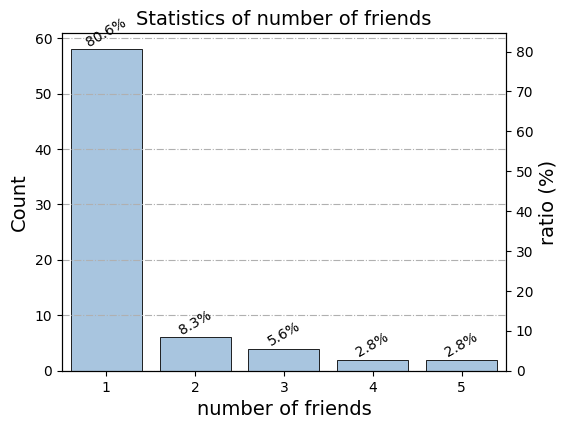

In [111]:
print(social_network_selected.friend_list.map(len).describe())
visual_statistics_discrete(social_network_selected.friend_list.map(len), "number of friends")

### Statistics of video features

count    10728.000000
mean         1.183166
std          0.436205
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          4.000000
Name: feat, dtype: float64


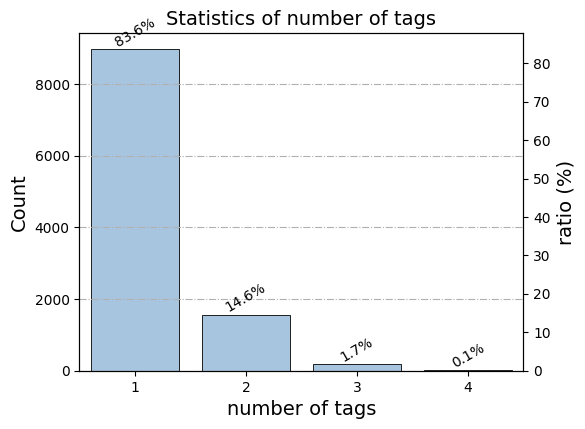

In [36]:
num_feat = item_categories.feat.map(len)
print(num_feat.describe())
visual_statistics_discrete(num_feat, "number of tags")

### Distribution of the 31 tags of items

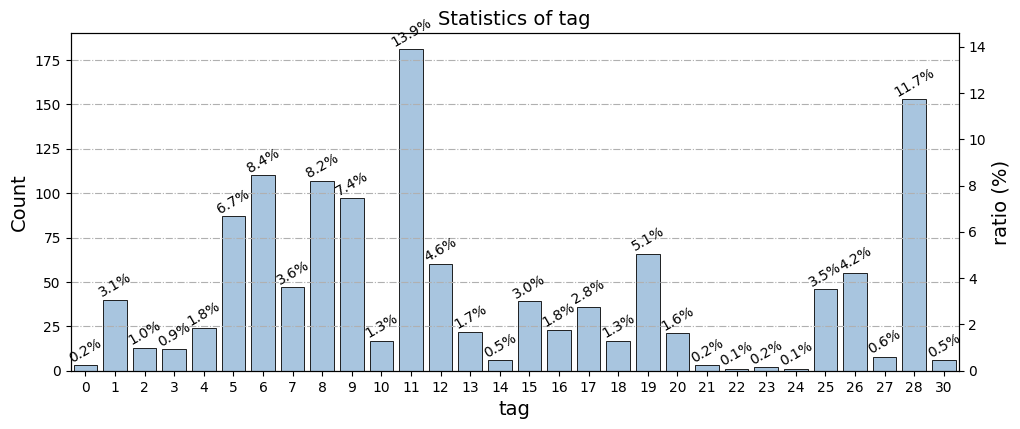

In [112]:
import collections
import itertools

cnt = item_categories_selected.feat.map(collections.Counter)
cnt_all = collections.Counter()
for d in cnt:
    cnt_all.update(d)
# print(dict(cnt_all))
all_feat = pd.Series(sorted(list(itertools.chain.from_iterable([[i]*k for i,k in cnt_all.items()]))),name="feat")
# print(all_feat)
visual_statistics_discrete(all_feat, "tag", size=(12,4.5))

### Distribution of watch_ratio in big matrix

count    1.241552e+07
mean     8.510664e-01
std      7.185296e-01
min      0.000000e+00
25%      3.111008e-01
50%      7.161066e-01
75%      1.161843e+00
max      5.000000e+00
Name: watch_ratio, dtype: float64


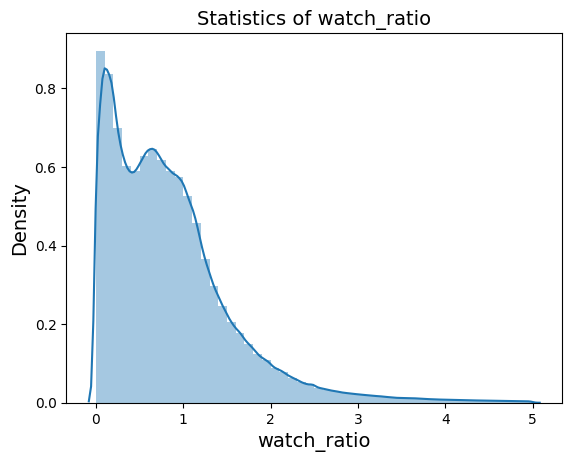

In [38]:
big_watch_ratio = big_matrix.watch_ratio[big_matrix.watch_ratio <= 5]
print(big_watch_ratio.describe())
visual_continue(big_watch_ratio)

### Distribution of watch_ratio in small matrix (in selected subsample)

count    1.884681e+06
mean     8.554661e-01
std      5.901807e-01
min      0.000000e+00
25%      4.702264e-01
50%      7.682505e-01
75%      1.113892e+00
max      5.000000e+00
Name: watch_ratio, dtype: float64


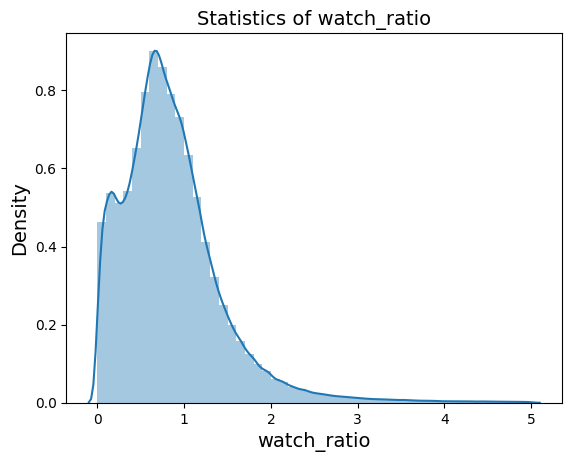

In [25]:
small_watch_ratio = df.watch_ratio[df.watch_ratio <= 5]
print(small_watch_ratio.describe())
visual_continue(small_watch_ratio)

### Distribution of video duration in the big matrix (in millisecond)

count    1.253081e+07
mean     1.462157e+04
std      1.983474e+04
min      1.400000e+02
25%      7.434000e+03
50%      9.636000e+03
75%      1.217900e+04
max      3.150720e+05
Name: video_duration, dtype: float64


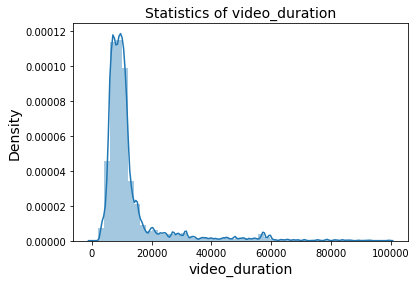

In [ ]:
big_video_duration = big_matrix.video_duration
print(big_video_duration.describe())
# visual_continue(big_video_duration)
visual_continue(big_video_duration[big_video_duration < 100000])

### Distribution of video duration in the small matrix (in millisecond)

count    1.894006e+06
mean     1.451370e+04
std      2.164899e+04
min      3.088000e+03
25%      7.534000e+03
50%      9.579000e+03
75%      1.183400e+04
max      3.150720e+05
Name: video_duration, dtype: float64


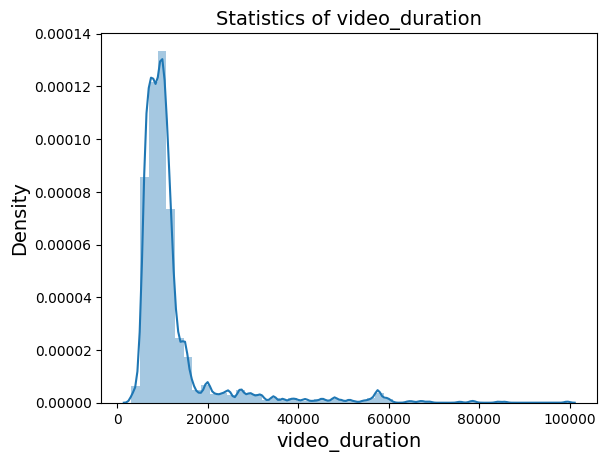

In [26]:
small_video_duration = df.video_duration
print(small_video_duration.describe())
# visual_continue(small_video_duration)
visual_continue(small_video_duration[small_video_duration < 100000])

### Distribution of each user's total play times in the big matrix

               date
count   7176.000000
mean    1746.210424
std      991.832222
min      100.000000
25%      883.000000
50%     1846.500000
75%     2461.000000
max    16015.000000


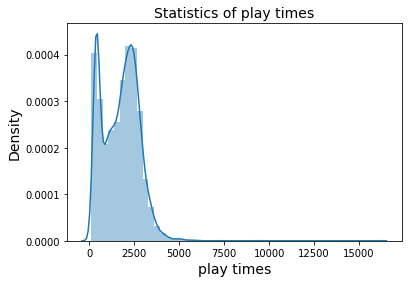

In [ ]:
big_play_time = big_matrix.groupby('user_id').agg({"date":len})
big_play_time.name = "play times"
print(big_play_time.describe())
visual_continue(big_play_time)

### Distribution of each user's total play times in the small matrix

              date
count  1411.000000
mean   3314.365698
std       6.984852
min    3295.000000
25%    3309.000000
50%    3315.000000
75%    3320.000000
max    3327.000000


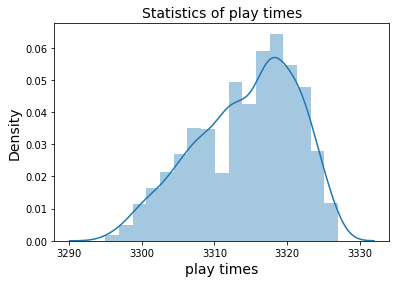

In [ ]:
small_play_time = small_matrix.groupby('user_id').agg({"date":len})
small_play_time.name = "play times"
print(small_play_time.describe())
visual_continue(small_play_time)

### Distribution of each user's daily play times in the big matrix

count    188322.000000
mean         66.539257
std          78.752240
min           1.000000
25%          19.000000
50%          42.000000
75%          83.000000
max        3268.000000
Name: play times, dtype: float64


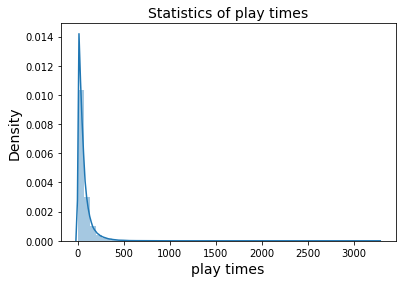

In [ ]:
big_daily_play_time = big_matrix.groupby(['user_id', 'date']).size()
big_daily_play_time.name = "play times"
print(big_daily_play_time.describe())
visual_continue(big_daily_play_time)

### Distribution of each user's daily play times in the small matrix

count    86671.000000
mean        51.857922
std         32.608372
min          1.000000
25%         28.000000
50%         47.000000
75%         70.000000
max        402.000000
Name: play times, dtype: float64


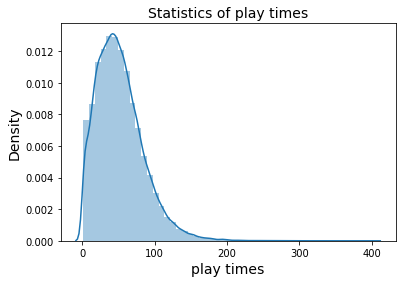

In [ ]:
small_daily_play_time = small_matrix.groupby(['user_id', 'date']).size()
small_daily_play_time.name = "play times"
print(small_daily_play_time.describe())
visual_continue(small_daily_play_time)

В результате проведения EDA анализа было решено использовать big_matrix в качестве обучающих и валидационных данных, а small_matrix - для тестовых. Предварительная подготовка состояла из:
1) Удаления взаимодействий без поля 'timestamp'. В small_matrix таких объектов оказалось $\approx 4\%$, в big_matrix - 0%.
2) Случайного выбора подмножества юзеров и айтемов с зафиксированным сидом.
3) Сортировки взаимодействий по столбцу 'timestamp' и отложить в обучающую выьорку 70% первых объектов, в валидационную - 15% следующих и в тестовую - последние 15%. Это необходимо, чтобы
4) Оставить в валидационной и тестовой выборке только тех юзеров и айтемы, которые были в обучающей. Так как реализуемые рекомендательные модели плохо работают в ситуации колдстарта - избавимся от такого сценария.

Таким образом получен даатсет, содержащий

# Метрики

Для

In [ ]:
import numpy as np


def recall_at_k(pred, test, k=10, threshold=0.5):
    relevant = test[test["watch_ratio"] >= threshold].groupby(
        "user_id"
    )["video_id"].apply(set)

    scores = []
    for user, items in relevant.items():
        recs = pred[
            pred["user_id"] == user
        ].nlargest(k, "predicted_score")["video_id"]

        scores.append(len(set(recs) & items) / len(items))

    return np.mean(scores) if scores else 0.0


def ndcg_at_k(pred, test, k=10):
    gains = test.groupby("user_id").apply(
        lambda x: dict(zip(x["video_id"], x["watch_ratio"]))
    ).to_dict()

    scores = []
    for user, group in pred.groupby("user_id"):
        ranked = group.nlargest(k, "predicted_score")["video_id"]
        user_gains = gains.get(user, {})

        dcg = sum(
            user_gains.get(item, 0) / np.log2(i + 2)
            for i, item in enumerate(ranked)
        )
        ideal = sorted(user_gains.values(), reverse=True)[:k]
        idcg = sum(
            gain / np.log2(i + 2)
            for i, gain in enumerate(ideal)
        )

        if idcg > 0:
            scores.append(dcg / idcg)

    return np.mean(scores) if scores else 0.0


# Модели

**Постановка задачи**

Пусть $U$ - множество пользователей, $I$ - множество видео. Обучающие данные содержат наблюдавшиеся взаимодействия
$$
D_{\mathrm{train}}=\{(u,i,t,r_{ui}): u\in U,\ i\in I\},
$$
где $t$ - временная метка, а $r_{ui}$ - отношение длительности просмотра к длительности видео ($\texttt{watch_ratio}$). Для ограничения влияния повторных просмотров в моделях, использующих непрерывный сигнал, можно применять

Определим взаимодействия по обучающей выборки:
$$
R_{ui}=\begin{cases}
r_{ui}, & (u,i)\in D_{\mathrm{train}},\\
0, & \text{иначе}.
\end{cases}
$$

Каждая модель вычисляет оценку $s(u,i)$ для кандидата $i$. Рекомендации пользователю - это десять допустимых видео с максимальными оценками:
$$
L_u^{10}=\operatorname{Top10}_{i\in I_{\mathrm{cand}}(u)}s(u,i).
$$

Для KuaiRec можно заранее определить бинарную релевантность на validation/test, например
$$
g_{ui}=\mathbb{1}[r_{ui}\geq 0.8].
$$
Порог $0.8$ - экспериментальный выбор, а не объективная метка удовлетворённости. Его нужно зафиксировать до сравнения моделей и использовать одинаково для всех методов. В качестве метрик ранжирования можно использовать Recall@10 и NDCG@10.

In [1]:
!unzip /content/KuaiRec_First_Three_Models.zip

Archive:  /content/KuaiRec_First_Three_Models.zip
   creating: KuaiRec_First_Three_Models/
  inflating: KuaiRec_First_Three_Models/smoke_test.py  
  inflating: KuaiRec_First_Three_Models/README.md  
   creating: KuaiRec_First_Three_Models/models/
  inflating: KuaiRec_First_Three_Models/models/ials.py  
  inflating: KuaiRec_First_Three_Models/models/ease.py  
  inflating: KuaiRec_First_Three_Models/models/user_cf.py  
  inflating: KuaiRec_First_Three_Models/models/common.py  
  inflating: KuaiRec_First_Three_Models/models/__init__.py  
   creating: KuaiRec_First_Three_Models/models/__pycache__/
  inflating: KuaiRec_First_Three_Models/models/__pycache__/__init__.cpython-313.pyc  
  inflating: KuaiRec_First_Three_Models/models/__pycache__/user_cf.cpython-313.pyc  
  inflating: KuaiRec_First_Three_Models/models/__pycache__/common.cpython-313.pyc  
  inflating: KuaiRec_First_Three_Models/models/__pycache__/ials.cpython-313.pyc  
  inflating: KuaiRec_First_Three_Models/models/__pycache__/eas

### Коллаборативная KNN фильтрация

**Описание подхода "User-based collaborative filtering"**


Метод предполагает, что пользователи с похожими историями взаимодействий могут иметь похожие интересы.


1.   *Fit*

        1.1.  Между всеми пользователями вычисляется близость но основании некоторой метрики, которая является гиперпараметром. Рассмотрим для примера косинусное сходство:

        $$
        \operatorname{sim}(u,v)=
        \frac{\displaystyle\sum_{i} r_{ui} r_{vi}}
        {\displaystyle
        \sqrt{\sum_{i} r_{ui}^{2}}
        \sqrt{\sum_{i} r_{vi}^{2}}}.
        $$
        Если знаменатель равен нулю или общих видео нет, сходство полагается равным нулю

        1.2.   Построим $N_k(u)$ - множество $k$ наиболее похожих пользователей с положительным сходством.
        $$ N_k(u) = \{v ≠ u : sim(u,v) > 0, |N_k(u)| = k \}$$
2.    *Predict*

        2.1. Для видео $i$, не наблюдавшегося у пользователя $u$ в train, вычисляется взвешенное среднее сигналов соседей:


        $$
        s(u,i)=
        \frac{\displaystyle\sum_{v\in N_k(u)}
        \operatorname{sim}(u,v) r_{vi}}
        {\displaystyle\sum_{v\in N_k(u)}
        \operatorname{sim}(u,v)},
        $$
        2.2. Для пользователя u рекомендуем топ-10 видео по полученным $s(u,i)$

*Гиперпараметры:*

*   Метрика близости пользователей $sim(u, v)$
*   Число соседей $k$


In [124]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

#беклог: корреляция пирсона, к поменять
#        проверить для скора нормировку

def recommend_userknn(df, user_col="user_id", item_col="video_id", feedback_col="watch_ratio", k=10, n=10):
    data = df.dropna(subset=[user_col, item_col, feedback_col])

    R = data.pivot_table(
        index=user_col, columns=item_col,
        values=feedback_col, fill_value=0, aggfunc="mean",
    )
    users, items = R.index.to_numpy(), R.columns.to_numpy()

    R = R.to_numpy(dtype=float)
    feedback  = (R != 0.0)          # watch_ratio==0 == нет взаимодействия

    sim = cosine_similarity(R)
    np.fill_diagonal(sim, 0.0)

    results = []

    for u in range(len(users)):
        nb = np.argpartition(-sim[u], k)[:k]  # top-k соседей
        w  = sim[u, nb]                                # (k,)
        feedback_nb, R_nb = feedback[nb], R[nb]                  # (k, n_items)

        num = (w[:, None] * R_nb  * feedback_nb).sum(axis=0)
        den = (w[:, None] * feedback_nb).sum(axis=0)

        score = np.divide(num, den,
                          out=np.full(len(items), -np.inf),
                          where=den > 0)
        score[feedback[u]] = -np.inf                        # не рекомендуем виденное

        top = np.argpartition(-score, n)[:n]
        for i in top:
            if score[i] > -np.inf:
                results.append((users[u], items[i], score[i]))

    recommendations = pd.DataFrame(
        results, columns=[user_col, item_col, "predicted_score"],
    )
    similarity_df = pd.DataFrame(sim, index=users, columns=users)
    return recommendations, similarity_df, R

In [125]:
recommendations, similarity_df, R = recommend_userknn(train_df)

In [77]:
recommendations

,user_id,video_id,predicted_score
0,14,733,1.971707
1,14,7135,1.802650
2,14,732,1.501061
3,14,4015,1.486513
4,14,723,1.462591
...,...,...,...
14105,7162,5626,1.575950
14106,7162,2472,1.552242
14107,7162,7046,1.550774
14108,7162,2267,1.541257


### ALS

**Описание подхода "Alternative Least Squares"**

Метод факторизует матрицу взаимодействия $R$ как произведение латентных матриц пользователей и видео:
$$
R \approx X Y^{\top},
  \qquad
  X \in \mathbb{R}^{u \times f},
  \quad
  Y \in \mathbb{R}^{i \times f},
$$
где $f$ - число латентных факторов. Возможность представления матрицы взаимодействий в виде произвденеия двух других матриц обосновывается через truncated SVD.

*Train*
1.  Инициализируем $X \in \mathbb{R}^{u \times f}, Y\in \mathbb{R}^{i \times f}$
2.  Минимизируем регуляризованную квадратичную ошибку на наблюдениях:
$$
  L(X,Y)
  =
  \sum_{(u,i)\in \Omega} \bigl(r_{ui} - x_u^{\top} y_i\bigr)^{2}
  +
  \lambda\Bigl(\|X\|^{2}_F + \|Y\|^{2}_F\Bigr),
$$
где $x_u$ - строка $X$, $y_i$ - строка $Y$.
Задача решается чередованием.

3.   Поочередная минимизация:

        3.1. Шаг по $X$.
        Фиксируем $Y$. Для каждого пользователя $u$ задача распадается
        на независимую регуляризованную линейную регрессию по просмотренным видео $\Omega_u$:
        $$ x_u = \bigl(Y_{\Omega_u}^{\top} Y_{\Omega_u} + \lambda I\bigr)^{-1} Y_{\Omega_u}^{\top} r_{u,\Omega_u}, $$
        где $Y_{\Omega_u}$ - подматрица $Y$ из строк с индексами $\Omega_u$,
        $r_{u,\Omega_u}$ - вектор сигналов $r_{ui}$, $i\in\Omega_u$.

        3.2. Шаг по $Y$.
        Симметрично, фиксируем $X$. Для каждого видео $i$:
        $$ y_i = \bigl(X_{\Omega^{i}}^{\top} X_{\Omega^{i}} + \lambda I\bigr)^{-1}
        X_{\Omega^{i}}^{\top} r_{\Omega^{i},i},
        $$
        где $\Omega^{i} = \{u : (u,i)\in\Omega\}$.

Шаги повторяются $n_{\text{iter}}$ раз.

*Predict*

Для пары $(u,i)\notin\Omega$ предсказание:
$$
  s(u,i) = x_u^{\top} y_i.
$$

 Для пользователя $u$ ранжируем непросмотренные им видео по $s(u,i)$
и рекомендуем топ-$N$.


Гиперпараметры:

*   число латентных факторов $f$;
*   коэффициент L2-регуляризации $\lambda$;
*   число итераций $n_{\text{iter}}$;


In [ ]:
import numpy as np
import pandas as pd


def recommend_als(
    df,
    user_col="user_id",
    item_col="video_id",
    feedback_col="watch_ratio",
    n_factors=20,
    n_iter=20,
    reg=0.1,
    n=10,
    random_state=42,
):
    data = df.dropna(subset=[user_col, item_col, feedback_col])

    # 1. user-item матрица
    R_df = data.pivot_table(
        index=user_col, columns=item_col,
        values=feedback_col, fill_value=0, aggfunc="mean",
    )
    users, items = R_df.index.to_numpy(), R_df.columns.to_numpy()

    R = R_df.to_numpy(dtype=float)
    observed = (R != 0.0)                          # маска «есть оценка»

    n_users, n_items = R.shape
    np.random.seed(SEED)
    X = np.random.normal(0.0, 0.01, size=(n_users, n_factors))   # user-факторы
    Y = np.random.normal(0.0, 0.01, size=(n_items, n_factors))   # item-факторы

    reg_I = reg * np.eye(n_factors)

    # 2. ALS: поочерёдно решаем линейную систему для X и для Y
    for _ in range(n_iter):

        # шаг по X: фиксируем Y, решаем для каждого пользователя
        #   X[u] = (Y_obs^T Y_obs + reg*I)^{-1} Y_obs^T r_obs
        for u in range(n_users):
            idx = np.flatnonzero(observed[u])    # айтемы, что u оценил
            if idx.size == 0:
                continue
            Y_obs = Y[idx]                       # (n_obs, f)
            r_obs = R[u, idx]                    # (n_obs,)
            A = Y_obs.T @ Y_obs + reg_I
            b = Y_obs.T @ r_obs
            X[u] = np.linalg.solve(A, b)

        # шаг по Y: фиксируем X, решаем для каждого айтема
        #   Y[i] = (X_obs^T X_obs + reg*I)^{-1} X_obs^T r_obs
        for i in range(n_items):
            idx = np.flatnonzero(observed[:, i]) # пользователи, что оценили i
            if idx.size == 0:
                continue
            X_obs = X[idx]
            r_obs = R[idx, i]
            A = X_obs.T @ X_obs + reg_I
            b = X_obs.T @ r_obs
            Y[i] = np.linalg.solve(A, b)

    # 3. предсказание — скалярное произведение факторов
    scores = X @ Y.T                             # (n_users, n_items)
    scores[observed] = -np.inf                   # уже виденное не рекомендуем

    # 4. top-N на пользователя — тот же приём, что в KNN
    results = []
    for u in range(n_users):
        top = np.argpartition(-scores[u], n - 1)[:n]
        top = top[scores[u, top] > -np.inf]
        top = top[np.argsort(-scores[u, top])]   # отсортировано по убыванию
        for i in top:
            results.append((users[u], items[i], scores[u, i]))

    recommendations = pd.DataFrame(
        results, columns=[user_col, item_col, "predicted_score"],
    )
    user_factors = pd.DataFrame(X, index=users)
    item_factors = pd.DataFrame(Y, index=items)
    return recommendations, user_factors, item_factors, R_df

### EASE

**Описание подхода "Embarrassingly Shallow Autoencoders for Sparse Data"**


Идея метода заключается в обучении линейного преобразования истории взаимодействия между пользователями и объектами в полную матрицу взаимодействий.

EASE - линейный автоэнкодер без скрытого слоя и без нелинейности:
вход - строка пользователя $r_u \in \mathbb{R}^{n_i}$, выход - $r_u B$,
где $B \in \mathbb{R}^{n_i \times n_i}$ - обученная матрица преобразования. Накладывается ограничение $\mathrm{diag}(B) = 0$, которое не дает модели тривиально скопировать вход.

*Fit*

1.   Инициализируем $B \in \mathbb{R}^{n_i \times n_i}$, так что $\mathrm{diag}(B) = 0$.
2.   Минимизируем регуляризованную ошибку реконструкции:
$$
  L(B) = \|R - R B\|_F^{2} + \lambda \|B\|_F^{2},
  \qquad
  \text{при } \mathrm{diag}(B) = 0.
$$
3.   Задача имеет замкнутое решение.

        Считаем матрицу Грама:
        $$
        G = R^{\top} R \in \mathbb{R}^{n_i \times n_i},
        \qquad
        P = (G + \lambda I)^{-1}.
        $$

        Строим $B$:
        $$
        B_{ij} = -\,\frac{P_{ij}}{P_{jj}}, \quad i \neq j,
        \qquad
        B_{ii} = 0.
        $$


Обучения как такового нет - одна инверсия матрицы размера
$n_i \times n_i$ и нормировка по столбцам.

*Predict*

 Для пары $(u,i) \notin \Omega$ предсказание:
$$
  s(u,i) = \bigl(r_{u,:} B\bigr)_i
         = \sum_{j:\,(u,j) \in \Omega} r_{uj}\, B_{ji}.
$$
Это скалярное произведение строки пользователя на $i$-й столбец $B$ -
линейная реконструкция сигнала по всем наблюдённым видео.

Для пользователя $u$ ранжируем непросмотренные им видео
по $s(u,i)$ и рекомендуем топ-$N$.

*Гиперпараметры*


*   коэффициент L2-регуляризации $\lambda$;



In [ ]:
import numpy as np
import pandas as pd


def recommend_ease(
    df,
    user_col="user_id",
    item_col="video_id",
    feedback_col="watch_ratio",
    reg=100.0,
    n_recommendations=10,
):
    data = df.dropna(subset=[user_col, item_col, feedback_col])

    # 1. user-item матрица: 0 = «нет взаимодействия»
    R_df = data.pivot_table(
        index=user_col, columns=item_col,
        values=feedback_col, fill_value=0, aggfunc="mean",
    )
    users, items = R_df.index.to_numpy(), R_df.columns.to_numpy()

    X = R_df.to_numpy(dtype=float)
    observed = X != 0.0                       # маска «есть оценка»

    # 2. EASE: B = argmin ‖X − X B‖² + reg·‖B‖²   s.t. diag(B)=0
    #    Закрытая формула: P = (XᵀX + reg·I)⁻¹;  B_ij = −P_ij / P_jj (i≠j)
    n_items = X.shape[1]
    G = X.T @ X                               # (n_items, n_items)
    P = np.linalg.inv(G + reg * np.eye(n_items))

    B = P / (-np.diag(P))                     # делим каждый столбец j на −P_jj
    np.fill_diagonal(B, 0.0)                  # себя не реконструируем

    # 3. предсказание — тоже матричное: (n_users, n_items)
    scores = X @ B
    scores[observed] = -np.inf                # уже виденное не рекомендуем

    # 4. top-N на пользователя — тот же приём, что в KNN/ALS
    n_eff = min(n_recommendations, n_items)
    results = []
    for u in range(len(users)):
        top = np.argpartition(-scores[u], n_eff - 1)[:n_eff]
        top = top[scores[u, top] > -np.inf]
        top = top[np.argsort(-scores[u, top])]
        for i in top:
            results.append((users[u], items[i], scores[u, i]))

    recommendations = pd.DataFrame(
        results, columns=[user_col, item_col, "predicted_score"],
    )
    item_weights = pd.DataFrame(B, index=items, columns=items)
    return recommendations, item_weights, R_df

### Факторизационные машины

\section{Модель 4: Factorization Machine (FM) с метапризнаками}

\subsection{Представление пары пользователь--видео}

Для каждой пары $(u,i)$ формируется вектор признаков $\mathbf x_{ui}\in\mathbb R^p$. Он включает ID пользователя и видео, а также доступные на момент рекомендации метапризнаки, например характеристики пользователя, ID автора, категорию и длительность видео. Категориальные поля кодируются индикаторами или другим фиксированным категориальным представлением; числовые признаки при необходимости масштабируются. Нельзя включать фактический целевой сигнал оцениваемого взаимодействия или признаки, вычисленные из будущих событий.

\subsection{Функция предсказания}

FM второго порядка вычисляет оценку
\[
\widehat y(\mathbf x)=w_0+\sum_{j=1}^{p}w_jx_j+
\sum_{j=1}^{p}\sum_{\ell=j+1}^{p}
\langle\mathbf v_j,\mathbf v_\ell\rangle x_jx_\ell,
\]
где $w_0\in\mathbb R$ --- смещение, $w_j\in\mathbb R$ --- линейные коэффициенты, а $\mathbf v_j\in\mathbb R^k$ --- латентный вектор признака $j$. Скалярное произведение $\langle\mathbf v_j,\mathbf v_\ell\rangle$ задаёт силу взаимодействия двух признаков.

Для эффективного вычисления попарного члена используется тождество
\[
\begin{aligned}
&\sum_{j=1}^{p}\sum_{\ell=j+1}^{p}
\langle\mathbf v_j,\mathbf v_\ell\rangle x_jx_\ell\\
&=\frac12\left\|\sum_{j=1}^{p}\mathbf v_jx_j\right\|_2^2
-\frac12\sum_{j=1}^{p}\|\mathbf v_j\|_2^2x_j^2.
\end{aligned}
\]
Это сокращает вычисление с явного перебора всех пар признаков до порядка $O(pk)$ для плотного вектора признаков; для разреженного представления расчёт зависит от числа активных признаков.

\subsection{Обучение}

В данной работе FM можно обучать как регрессию непрерывного сигнала $\tilde r_{ui}$ на наблюдавшихся взаимодействиях:
\[
\begin{aligned}
\min_{w_0,w,V}\quad &
\sum_{(u,i)\in\mathcal D_{\mathrm{train}}}
\left(\tilde r_{ui}-\widehat y(\mathbf x_{ui})\right)^2\\
&+\lambda_w\|w\|_2^2+
\lambda_v\sum_{j=1}^{p}\|\mathbf v_j\|_2^2.
\end{aligned}
\]
Параметры обучаются градиентным методом, например с помощью autograd в PyTorch, при самостоятельно реализованной формуле FM. Для ранжирования каждому кандидату формируется вектор метапризнаков $\mathbf x_{ui}$, а видео сортируются по $\widehat y(\mathbf x_{ui})$. Метапризнаки позволяют делать прогноз для нового видео или пользователя только тогда, когда для них доступны информативные признаки, а обученная модель способна использовать эти признаки без известного ID.

\section{Модель 5: iALS с собственным целевым сигналом}

\subsection{Мотивация}

В базовой iALS все наблюдавшиеся пары имеют целевое значение $1$, поэтому различие между коротким и длительным просмотром напрямую не отражается в цели. В модифицированной модели используется степень просмотра как непрерывный сигнал предпочтения.

Для наблюдавшихся пар определим
\[
y_{ui}^{\mathrm{custom}}=
\begin{cases}
\min\{1,\max\{0,r_{ui}\}\},&M_{ui}=1,\\
0,&M_{ui}=0.
\end{cases}
\]
При этом уверенность оставим такой же, как в базовой модели:
\[
c_{ui}=1+\alpha M_{ui}.
\]
Таким образом, сравнение изолирует изменение целевого сигнала, а не изменение confidence-весов.

\subsection{Целевая функция}

\[
\begin{aligned}
\min_{P,Q}\quad &
\sum_{u\in U}\sum_{i\in I}
 c_{ui}\bigl(y_{ui}^{\mathrm{custom}}-\mathbf p_u^{\mathsf T}\mathbf q_i\bigr)^2\\
&+\lambda\left(\sum_{u\in U}\|\mathbf p_u\|_2^2+
\sum_{i\in I}\|\mathbf q_i\|_2^2\right).
\end{aligned}
\]
Оптимизация выполняется тем же алгоритмом ALS, что и для базовой iALS, но вместо бинарного $y_{ui}^{\mathrm{bin}}$ используется $y_{ui}^{\mathrm{custom}}$. Параметры инициализации, confidence-веса и регуляризация подбираются по тому же протоколу, что и для базовой модели.

Экспериментальный вопрос: улучшает ли использование степени просмотра качество персонального top-10 относительно бинарного сигнала о факте взаимодействия? Для корректного ответа базовая iALS и модифицированная iALS должны использовать одинаковые разбиения, множество пользователей и кандидатов, а test-релевантность должна быть определена единообразно, например через $r_{ui}\geq0.8$.

\section{Общий протокол оценки}

Для каждого пользователя формируется top-10 среди допустимых кандидатов после исключения объектов, встречавшихся в его обучающей истории. Например, Recall@10 рассчитывается как
\[
\operatorname{Recall@10}(u)=
\frac{|L_u^{10}\cap G_u|}{|G_u|},
\]
где $L_u^{10}$ --- рекомендованные десять видео, $G_u$ --- множество релевантных видео пользователя в оцениваемом временном периоде. NDCG@10 учитывает также позиции релевантных объектов:
\[
\operatorname{DCG@10}(u)=\sum_{j=1}^{10}
\frac{2^{g_{u,i_j}}-1}{\log_2(j+1)},
\qquad
\operatorname{NDCG@10}(u)=
\frac{\operatorname{DCG@10}(u)}{\operatorname{IDCG@10}(u)}.
\]
Здесь $i_j$ --- видео на позиции $j$, $g_{u,i_j}\in\{0,1\}$ --- единый тестовый индикатор релевантности, а $\operatorname{IDCG@10}$ --- максимально возможный DCG@10 при идеальном порядке релевантных объектов.

Гиперпараметры всех моделей выбираются по validation. Test используется только для итогового сравнения. В отчёте следует зафиксировать seed, способ формирования подвыборки, временные границы, критерий релевантности, правила исключения уже известных объектов и выбранные гиперпараметры.